In [2]:
import torch
import math
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))

In [32]:
query = torch.rand(1, 3, 4)
key = torch.rand(1, 3, 4)
value = torch.rand(1, 3, 4)
d_k = query.shape[-1]
score = torch.matmul(query, torch.transpose(key, -1, -2))
scaled_score = score / math.sqrt(d_k)
weighted_score = torch.softmax(scaled_score, dim=-1)
output = torch.matmul(weighted_score, value)
output

tensor([[[0.5991, 0.4379, 0.7318, 0.6124],
         [0.6029, 0.4458, 0.7454, 0.6275],
         [0.6000, 0.4517, 0.7513, 0.6355]]])

In [37]:
query = torch.rand(1, 3, 4)
query.sum(axis=2)

tensor([[1.8040, 1.3948, 1.6355]])

In [38]:
torch.ones(2, 6)

tensor([[1., 1., 1., 1., 1., 1.],
        [1., 1., 1., 1., 1., 1.]])

In [7]:
ones_ = torch.ones(4, 4, dtype=torch.int32)
mask = torch.tril(ones_, diagonal=0).bool()
ones_ == mask

tensor([[ True, False, False, False],
        [ True,  True, False, False],
        [ True,  True,  True, False],
        [ True,  True,  True,  True]])

In [10]:
mask = torch.tril(torch.ones(5, 5, dtype=torch.bool))
sample = torch.tril(torch.ones(5, 5, dtype=torch.bool))

In [14]:
import numpy as np
assert mask.all() == sample.all()

In [8]:
import torch
weights = torch.tensor([
    [1, 0, 0],
    [1, 1, 0],
    [1, 1, 1]
])
upper_part = torch.tril(weights)
upper_part
# torch.all(upper_part == 0)

tensor([[1, 0, 0],
        [1, 1, 0],
        [1, 1, 1]])

In [11]:
from transformer.attention import attention
from transformer.masks import causal_mask
query = torch.rand(2, 6, 4)  # (batch, T_q, d_k)
key = torch.rand(2, 6, 4)  # (batch, T_k, d_k)
value = torch.rand(2, 6, 4)  # (batch, T_k, d_v)
_, weights = attention(query, key, value, mask=causal_mask(6))
weights

tensor([[[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
         [0.5563, 0.4437, 0.0000, 0.0000, 0.0000, 0.0000],
         [0.3737, 0.2767, 0.3496, 0.0000, 0.0000, 0.0000],
         [0.3006, 0.2184, 0.2628, 0.2182, 0.0000, 0.0000],
         [0.2123, 0.1866, 0.2012, 0.1857, 0.2142, 0.0000],
         [0.2042, 0.1365, 0.1776, 0.1358, 0.2019, 0.1439]],

        [[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
         [0.5124, 0.4876, 0.0000, 0.0000, 0.0000, 0.0000],
         [0.3135, 0.3629, 0.3237, 0.0000, 0.0000, 0.0000],
         [0.2634, 0.2278, 0.2467, 0.2621, 0.0000, 0.0000],
         [0.1907, 0.2266, 0.2012, 0.2112, 0.1703, 0.0000],
         [0.1579, 0.1777, 0.1477, 0.1791, 0.1567, 0.1809]]])

In [15]:
torch.all(torch.triu(weights, diagonal=1) == 0)

tensor(True)

In [16]:
torch.testing.assert_close(torch.triu(weights, diagonal=1), torch.zeros_like(weights))

In [17]:
query = torch.rand(1, 5, 3)  # (batch, T_q, d_k)
key = torch.rand(1, 4, 3)  # (batch, T_k, d_k)
value = torch.rand(1, 4, 3)  # (batch, T_k, d_v)
mask = torch.tensor([
        [True, True, False, False],
        [True, True, False, False],
        [True, True, False, False],
        [True, True, False, False],
        [True, True, False, False]
])
_, weights = attention(query, key, value, mask=mask)
weights

tensor([[[0.4368, 0.5632, 0.0000, 0.0000],
         [0.3901, 0.6099, 0.0000, 0.0000],
         [0.3639, 0.6361, 0.0000, 0.0000],
         [0.3384, 0.6616, 0.0000, 0.0000],
         [0.4216, 0.5784, 0.0000, 0.0000]]])

In [19]:
weights[:, :, -2:].sum() == 0

tensor(True)

In [20]:
q1 = torch.rand(2, 6, 4)
k1 = torch.rand(2, 6, 4)
v1 = torch.rand(2, 6, 4)
out1, _ = attention(q1, k1, v1, mask=causal_mask(6))
k2 = k1.clone()
v2 = v1.clone()
k2[:, 5, :] = 0.0034
v2[:, 5, :] = 0.0026
out2, _ = attention(q1, k2, v2, mask=causal_mask(6))

In [21]:
out1

tensor([[[0.6749, 0.2025, 0.9995, 0.1374],
         [0.8360, 0.3266, 0.4552, 0.1896],
         [0.8888, 0.2603, 0.5605, 0.3534],
         [0.8569, 0.3048, 0.5439, 0.4066],
         [0.8518, 0.3215, 0.5456, 0.4647],
         [0.7121, 0.3536, 0.5001, 0.4230]],

        [[0.1763, 0.1720, 0.0192, 0.7227],
         [0.0869, 0.3697, 0.4931, 0.4683],
         [0.0746, 0.3910, 0.5711, 0.4363],
         [0.0541, 0.4028, 0.6727, 0.3884],
         [0.2038, 0.4652, 0.6515, 0.3356],
         [0.2715, 0.4854, 0.7151, 0.3781]]])

In [22]:
out2

tensor([[[0.6749, 0.2025, 0.9995, 0.1374],
         [0.8360, 0.3266, 0.4552, 0.1896],
         [0.8888, 0.2603, 0.5605, 0.3534],
         [0.8569, 0.3048, 0.5439, 0.4066],
         [0.8518, 0.3215, 0.5456, 0.4647],
         [0.7611, 0.2887, 0.4793, 0.4051]],

        [[0.1763, 0.1720, 0.0192, 0.7227],
         [0.0869, 0.3697, 0.4931, 0.4683],
         [0.0746, 0.3910, 0.5711, 0.4363],
         [0.0541, 0.4028, 0.6727, 0.3884],
         [0.2038, 0.4652, 0.6515, 0.3356],
         [0.1741, 0.4276, 0.6095, 0.3033]]])

In [27]:
out1[:, 5, :]

tensor([[0.7121, 0.3536, 0.5001, 0.4230],
        [0.2715, 0.4854, 0.7151, 0.3781]])

In [25]:
out2[:, 5, :]

tensor([[0.7611, 0.2887, 0.4793, 0.4051],
        [0.1741, 0.4276, 0.6095, 0.3033]])

In [29]:
torch.all(out1[:, 5, :] != out2[:, 5, :])

tensor(True)

In [51]:
import torch.nn.functional as F

q = torch.rand(2, 3, 5, 4)
k = torch.rand(2, 3, 7, 4)
v = torch.rand(2, 3, 7, 6)
torch_out1 = F.scaled_dot_product_attention(q, k, v)
out1, _ = attention(q, k, v)

In [52]:
torch_out1

tensor([[[[0.5883, 0.4390, 0.4395, 0.3796, 0.6302, 0.6491],
          [0.6061, 0.4218, 0.4120, 0.3963, 0.6358, 0.6390],
          [0.5900, 0.4241, 0.4386, 0.3723, 0.6315, 0.6539],
          [0.6007, 0.4241, 0.4250, 0.3789, 0.6345, 0.6475],
          [0.6020, 0.4143, 0.4187, 0.3909, 0.6364, 0.6476]],

         [[0.5832, 0.7107, 0.7169, 0.6048, 0.4906, 0.3765],
          [0.6019, 0.7120, 0.7188, 0.5701, 0.5095, 0.3448],
          [0.5792, 0.7119, 0.7149, 0.6084, 0.5024, 0.3763],
          [0.5890, 0.7055, 0.7294, 0.6039, 0.4734, 0.3772],
          [0.5922, 0.6876, 0.7352, 0.5834, 0.4902, 0.3622]],

         [[0.7174, 0.5744, 0.5481, 0.4855, 0.5280, 0.6681],
          [0.7043, 0.5904, 0.5470, 0.5059, 0.4852, 0.6513],
          [0.7139, 0.5867, 0.5436, 0.4879, 0.5070, 0.6679],
          [0.7140, 0.5819, 0.5448, 0.4888, 0.5167, 0.6700],
          [0.7171, 0.5792, 0.5487, 0.4838, 0.5169, 0.6634]]],


        [[[0.4363, 0.3147, 0.5311, 0.5673, 0.5646, 0.4847],
          [0.4439, 0.3143, 0.540

In [53]:
out1

tensor([[[[0.5883, 0.4390, 0.4395, 0.3796, 0.6302, 0.6491],
          [0.6061, 0.4218, 0.4120, 0.3963, 0.6358, 0.6390],
          [0.5900, 0.4241, 0.4386, 0.3723, 0.6315, 0.6539],
          [0.6007, 0.4241, 0.4250, 0.3789, 0.6345, 0.6475],
          [0.6020, 0.4143, 0.4187, 0.3909, 0.6364, 0.6476]],

         [[0.5832, 0.7107, 0.7169, 0.6048, 0.4906, 0.3765],
          [0.6019, 0.7120, 0.7188, 0.5701, 0.5095, 0.3448],
          [0.5792, 0.7119, 0.7149, 0.6084, 0.5024, 0.3763],
          [0.5890, 0.7055, 0.7294, 0.6039, 0.4734, 0.3772],
          [0.5922, 0.6876, 0.7352, 0.5834, 0.4902, 0.3622]],

         [[0.7174, 0.5744, 0.5481, 0.4855, 0.5280, 0.6681],
          [0.7043, 0.5904, 0.5470, 0.5059, 0.4852, 0.6513],
          [0.7139, 0.5867, 0.5436, 0.4879, 0.5070, 0.6679],
          [0.7140, 0.5819, 0.5448, 0.4888, 0.5167, 0.6700],
          [0.7171, 0.5792, 0.5487, 0.4838, 0.5169, 0.6634]]],


        [[[0.4363, 0.3147, 0.5311, 0.5673, 0.5646, 0.4847],
          [0.4439, 0.3143, 0.540

In [54]:
torch.testing.assert_close(torch_out1, out1)

In [47]:
q = torch.rand(2, 5, 4)
k = torch.rand(2, 5, 4)
v = torch.rand(2, 5, 4)
torch_out2 = F.scaled_dot_product_attention(q, k, v, attn_mask=causal_mask(5))
out2, _ = attention(q, k, v, mask=causal_mask(5))

In [48]:
torch_out2

tensor([[[0.5071, 0.7314, 0.9895, 0.3191],
         [0.3202, 0.8397, 0.9897, 0.3375],
         [0.5278, 0.6513, 0.9080, 0.4730],
         [0.4039, 0.7094, 0.9157, 0.4484],
         [0.4173, 0.7485, 0.9103, 0.4740]],

        [[0.4014, 0.1468, 0.3278, 0.6244],
         [0.4682, 0.5104, 0.4754, 0.3954],
         [0.3779, 0.6689, 0.4042, 0.5515],
         [0.2801, 0.5964, 0.4217, 0.4030],
         [0.3857, 0.4976, 0.4510, 0.5345]]])

In [49]:
out2

tensor([[[0.5071, 0.7314, 0.9895, 0.3191],
         [0.3202, 0.8397, 0.9897, 0.3375],
         [0.5278, 0.6513, 0.9080, 0.4730],
         [0.4039, 0.7094, 0.9157, 0.4484],
         [0.4173, 0.7485, 0.9103, 0.4740]],

        [[0.4014, 0.1468, 0.3278, 0.6244],
         [0.4682, 0.5104, 0.4754, 0.3954],
         [0.3779, 0.6689, 0.4042, 0.5515],
         [0.2801, 0.5964, 0.4217, 0.4030],
         [0.3857, 0.4976, 0.4510, 0.5345]]])

In [50]:
torch.testing.assert_close(torch_out2, out2)

In [55]:
value = torch.randn(1, 2, 3)
value

tensor([[[ 0.9683, -0.3118,  0.7611],
         [ 0.9733, -1.7958, -0.6214]]])

In [57]:
value.mean(dim=1) 

tensor([[ 0.9708, -1.0538,  0.0698]])

In [2]:
import torch
B, T_q, T_k = 2, 5, 7
d_model, h = 6, 3
query = torch.rand(B, T_q, d_model)
query

tensor([[[0.7128, 0.9355, 0.3501, 0.8813, 0.8156, 0.6858],
         [0.5440, 0.2879, 0.1172, 0.0044, 0.9872, 0.4320],
         [0.1108, 0.6022, 0.1222, 0.4421, 0.3054, 0.8992],
         [0.8688, 0.8303, 0.6077, 0.8407, 0.2727, 0.8564],
         [0.8695, 0.7853, 0.0142, 0.8231, 0.2790, 0.1765]],

        [[0.3049, 0.4004, 0.5114, 0.6670, 0.7688, 0.5173],
         [0.7681, 0.1414, 0.8371, 0.3097, 0.8534, 0.2110],
         [0.7833, 0.2136, 0.3959, 0.0172, 0.5502, 0.2099],
         [0.2237, 0.1372, 0.9421, 0.5596, 0.1117, 0.6965],
         [0.9226, 0.3095, 0.2346, 0.6790, 0.2856, 0.8327]]])

In [3]:
import torch
B, T, d_model, h = 1, 3, 4, 2
d_k = d_model // h
query = torch.arange(0, 12).reshape(B, T, d_model)
# Head 1 should be: [[0, 1], [4, 5], [8, 9]]
output1 = query.reshape(B, h, T, d_k)
intermediate = query.reshape(B, T, h, d_k)
output2 = intermediate.transpose(1, 2)
query, output1, intermediate, output2

(tensor([[[ 0,  1,  2,  3],
          [ 4,  5,  6,  7],
          [ 8,  9, 10, 11]]]),
 tensor([[[[ 0,  1],
           [ 2,  3],
           [ 4,  5]],
 
          [[ 6,  7],
           [ 8,  9],
           [10, 11]]]]),
 tensor([[[[ 0,  1],
           [ 2,  3]],
 
          [[ 4,  5],
           [ 6,  7]],
 
          [[ 8,  9],
           [10, 11]]]]),
 tensor([[[[ 0,  1],
           [ 4,  5],
           [ 8,  9]],
 
          [[ 2,  3],
           [ 6,  7],
           [10, 11]]]]))

In [11]:
query = query.to(dtype=torch.float32)
query.mean(dim=2)
query.var(dim=2)

tensor([[1.6667, 1.6667, 1.6667]])

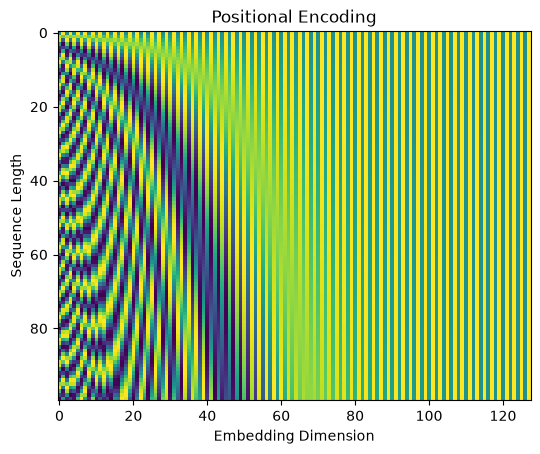

In [ ]:
from transformer.layers import PositionalEncoding
import matplotlib.pyplot as plt

d_model = 128
max_len = 100
pe = PositionalEncoding(d_model, max_len, 0)
plt.imshow(pe.lookup_table)
plt.ylabel('Sequence Length')
plt.xlabel('Embedding Dimension')
plt.title('Positional Encoding')
plt.savefig('./../assets/positional_encoding.png')